In [1]:
!apt-get update -qq
!apt-get install -y tesseract-ocr
!pip install pytesseract opencv-python matplotlib

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (5.3.4-1build5).
0 upgraded, 0 newly installed, 0 to remove and 24 not upgraded.


In [5]:

import cv2
import numpy as np
import pandas as pd
import pytesseract
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display


In [27]:

uploaded = files.upload()

nama_file = next(iter(uploaded))

print("Nama file:", nama_file)


Saving WhatsApp Image 2026-09-18 at 14.07.19 (2).jpeg to WhatsApp Image 2026-09-18 at 14.07.19 (2).jpeg
Nama file: WhatsApp Image 2026-09-18 at 14.07.19 (2).jpeg


Lebar gambar : 1008 piksel
Tinggi gambar: 720 piksel


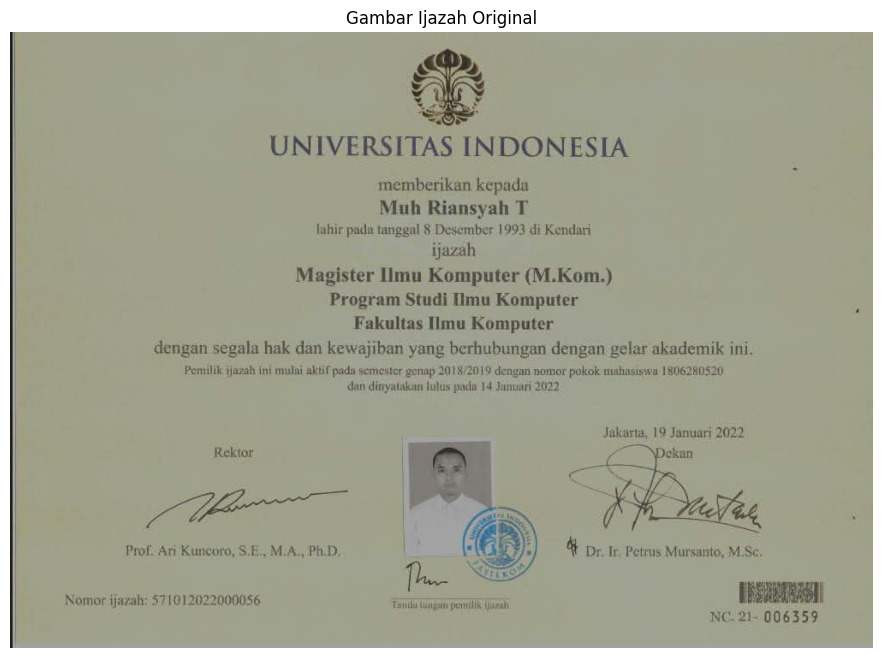

In [28]:

citra = cv2.imread(nama_file)

if citra is None:
    raise ValueError("Gambar gagal dibaca. Silakan upload ulang.")

tinggi, lebar = citra.shape[:2]

print("Lebar gambar :", lebar, "piksel")
print("Tinggi gambar:", tinggi, "piksel")

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(citra, cv2.COLOR_BGR2RGB))
plt.title("Gambar Ijazah Original")
plt.axis("off")
plt.show()


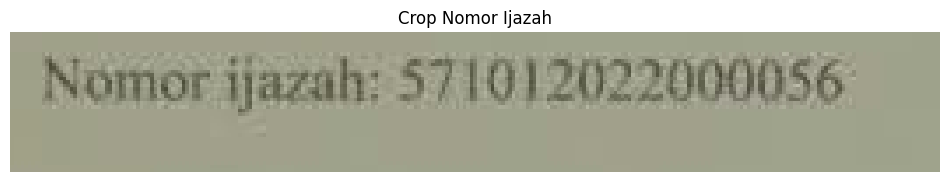

In [29]:
import cv2
import matplotlib.pyplot as plt

# Menggunakan variabel nama_file yang berisi file gambar yang diunggah sebelumnya
img = cv2.imread(nama_file)

if img is None:
    raise ValueError(f"Gambar {nama_file} tidak ditemukan. Pastikan file sudah terunggah.")

# Crop HANYA bagian nomor ijazah
crop_nomor = img[650:690, 55:320]

plt.figure(figsize=(12, 3))
plt.imshow(cv2.cvtColor(crop_nomor, cv2.COLOR_BGR2RGB))
plt.title("Crop Nomor Ijazah")
plt.axis("off")
plt.show()

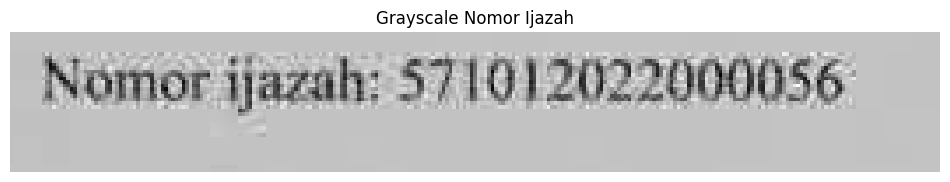

In [30]:
gray = cv2.cvtColor(crop_nomor, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(12, 3))
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Nomor Ijazah")
plt.axis("off")
plt.show()

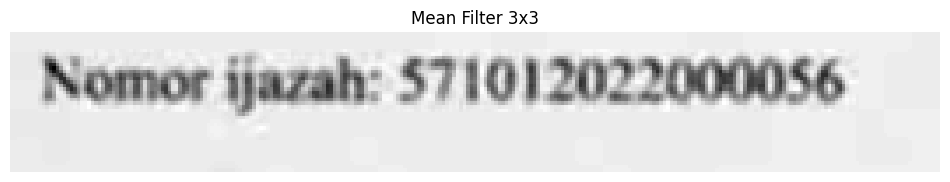

In [31]:
mean_filter = cv2.blur(gray, (3, 3))

plt.figure(figsize=(12, 3))
plt.imshow(mean_filter, cmap="gray")
plt.title("Mean Filter 3x3")
plt.axis("off")
plt.show()

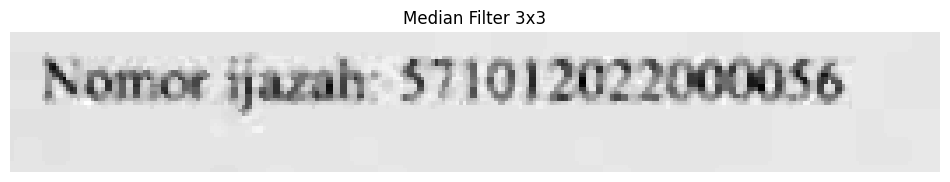

In [32]:
median_filter = cv2.medianBlur(gray, 3)

plt.figure(figsize=(12, 3))
plt.imshow(median_filter, cmap="gray")
plt.title("Median Filter 3x3")
plt.axis("off")
plt.show()

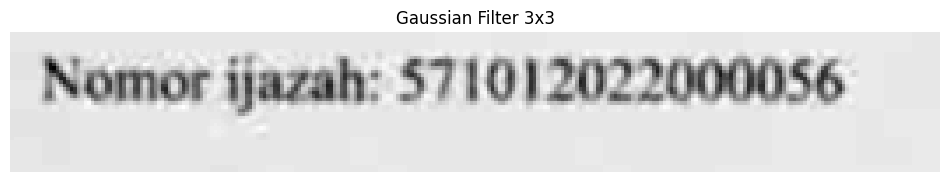

In [33]:
gaussian_filter = cv2.GaussianBlur(
    gray,
    (3, 3),
    0
)

plt.figure(figsize=(12, 3))
plt.imshow(gaussian_filter, cmap="gray")
plt.title("Gaussian Filter 3x3")
plt.axis("off")
plt.show()

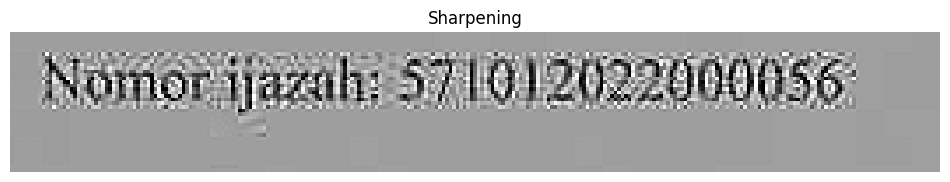

In [34]:
kernel_sharpen = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

sharpened = cv2.filter2D(
    gray,
    -1,
    kernel_sharpen
)

plt.figure(figsize=(12, 3))
plt.imshow(sharpened, cmap="gray")
plt.title("Sharpening")
plt.axis("off")
plt.show()

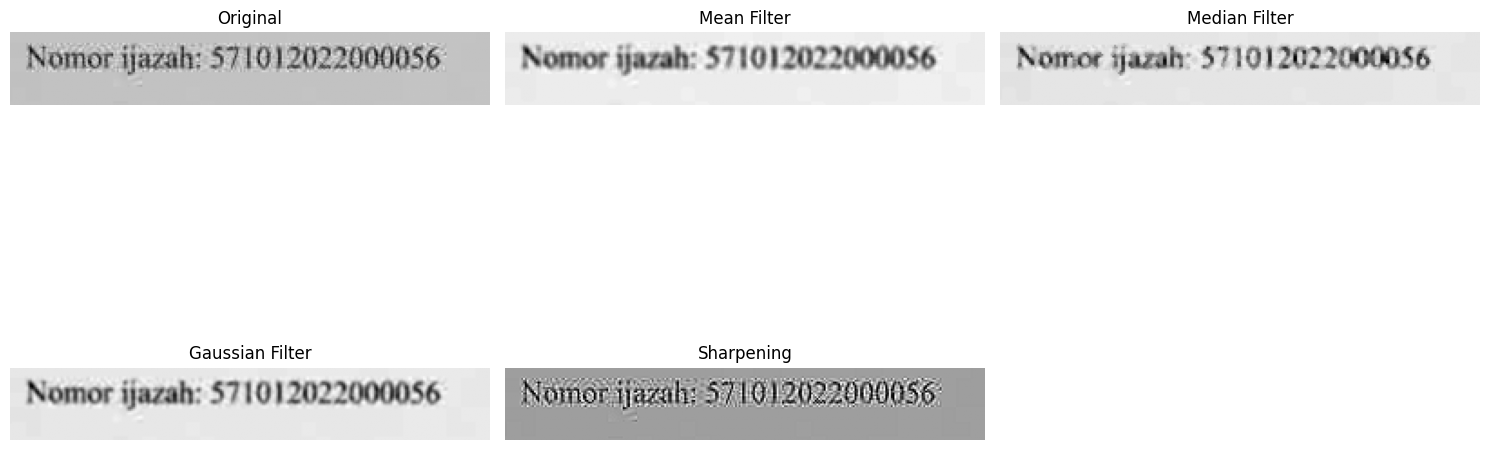

In [35]:
plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(mean_filter, cmap="gray")
plt.title("Mean Filter")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(median_filter, cmap="gray")
plt.title("Median Filter")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(gaussian_filter, cmap="gray")
plt.title("Gaussian Filter")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(sharpened, cmap="gray")
plt.title("Sharpening")
plt.axis("off")

plt.tight_layout()
plt.show()

In [36]:
def lakukan_ocr(image):

    # Memperbesar gambar agar karakter lebih mudah dikenali
    image = cv2.resize(
        image,
        None,
        fx=3,
        fy=3,
        interpolation=cv2.INTER_CUBIC
    )

    # OCR hanya angka
    config = "--psm 7 -c tessedit_char_whitelist=0123456789"

    text = pytesseract.image_to_string(
        image,
        config=config
    )

    # Ambil hanya angka
    text = re.sub(r'[^0-9]', '', text)

    return text

In [37]:
import re

ocr_original = lakukan_ocr(gray)

ocr_mean = lakukan_ocr(mean_filter)

ocr_median = lakukan_ocr(median_filter)

ocr_gaussian = lakukan_ocr(gaussian_filter)

ocr_sharpen = lakukan_ocr(sharpened)

In [39]:
print("Original      :", ocr_original)
print("Mean Filter   :", ocr_mean)
print("Median Filter :", ocr_median)
print("Gaussian      :", ocr_gaussian)
print("Sharpening    :", ocr_sharpen)

Original      : 571012022000056
Mean Filter   : 571012022000056
Median Filter : 571012022000056
Gaussian      : 571012022000056
Sharpening    : 971012022000056


In [40]:
ground_truth = "571012022000056"

In [41]:
def levenshtein_distance(a, b):

    m = len(a)
    n = len(b)

    dp = [[0] * (n + 1) for _ in range(m + 1)]

    for i in range(m + 1):
        dp[i][0] = i

    for j in range(n + 1):
        dp[0][j] = j

    for i in range(1, m + 1):
        for j in range(1, n + 1):

            if a[i - 1] == b[j - 1]:
                cost = 0
            else:
                cost = 1

            dp[i][j] = min(
                dp[i - 1][j] + 1,
                dp[i][j - 1] + 1,
                dp[i - 1][j - 1] + cost
            )

    return dp[m][n]

In [42]:
def hitung_akurasi(ground_truth, hasil_ocr):

    distance = levenshtein_distance(
        ground_truth,
        hasil_ocr
    )

    karakter_benar = max(
        0,
        len(ground_truth) - distance
    )

    akurasi = (
        karakter_benar / len(ground_truth)
    ) * 100

    return karakter_benar, akurasi

In [43]:
hasil_ocr = {
    "Original": ocr_original,
    "Mean Filter": ocr_mean,
    "Median Filter": ocr_median,
    "Gaussian Filter": ocr_gaussian,
    "Sharpening": ocr_sharpen
}

data = []

for metode, hasil in hasil_ocr.items():

    karakter_benar, akurasi = hitung_akurasi(
        ground_truth,
        hasil
    )

    data.append([
        metode,
        hasil,
        karakter_benar,
        round(akurasi, 2)
    ])

df = pd.DataFrame(
    data,
    columns=[
        "Metode",
        "Hasil OCR",
        "Karakter Benar",
        "Akurasi (%)"
    ]
)

df

,Metode,Hasil OCR,Karakter Benar,Akurasi (%)
0,Original,571012022000056,15,100.00
1,Mean Filter,571012022000056,15,100.00
2,Median Filter,571012022000056,15,100.00
3,Gaussian Filter,571012022000056,15,100.00
4,Sharpening,971012022000056,14,93.33
